# Modelado y evaluación (CRISP-DM)

Continúa `01_comprension_y_preparacion.ipynb`. Cubre las fases 4 y 5 de **CRISP-DM**:

4. **Modelado**: línea base (promedio móvil) y los candidatos del informe (regresión con
   calendario, en dos versiones, y ARIMA semanal).
5. **Evaluación**: backtesting con origen móvil, comparación contra un desempeño mínimo fijado
   antes de ver los resultados, confirmación con un dataset no mirado y elección documentada.

El dataset es **sintético** (`DATASET.md`): los resultados miden qué tan bien cada modelo aprende
la pyme simulada, no una pyme real. La justificación completa está en `MODELO.md`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from cashpyme_modelos.evaluacion import MEJORA_MINIMA, UMBRAL_ERROR_30, confirmar, elegir, evaluar, origenes_mensuales
from cashpyme_modelos.modelos import RegresionCalendario, candidatos

leer = lambda archivo: pd.read_csv(RAIZ / "datos" / archivo, parse_dates=["fecha"], index_col="fecha")[["ingresos", "egresos"]]
serie = leer("flujo_diario_sintetico.csv")
serie_confirmacion = leer("flujo_diario_confirmacion.csv")  # otra simulación, no mirada antes
guardado = json.loads((RAIZ / "resultados" / "comparacion_modelos.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.figsize": (11, 3.8), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
COLORES = {"Promedio móvil 28 días (línea base)": "#888780", "Regresión con calendario": "#2a78d6",
           "Regresión con calendario (alfa por validación interna)": "#1d9e75",
           "ARIMA semanal (SARIMA)": "#eb6834"}
pesos = lambda v, _=None: f"${v:,.0f}".replace(",", ".")

## 4. Modelado

| Modelo | Qué hace | Qué sabe del calendario |
|---|---|---|
| **Promedio móvil 28 días** (línea base) | Cada día futuro vale el promedio de los últimos 28 días | Nada |
| **Regresión con calendario** | Ridge sobre tendencia, día de la semana, mes, día del mes, feriado y último día hábil | Todo lo que se sabe de una fecha futura |
| **Regresión con alfa por validación interna** | La misma regresión, pero en cada entrenamiento elige alfa (0,1 a 100) con un backtest de los últimos 6 meses de esa historia | Lo mismo que la regresión |
| **ARIMA semanal** | SARIMA(1,0,1)(1,0,1)[7] con la variable *cerrado* | El ciclo semanal y los días cerrados |

Todos proyectan ingresos y egresos por separado; el flujo neto es la resta. Prophet (el otro
candidato del informe) no se incluyó: ver `MODELO.md`.

## 5. Evaluación

### Reglas, fijadas antes de comparar

In [2]:
print(f"Desempeño mínimo: error del flujo acumulado a 30 días <= {UMBRAL_ERROR_30:.0%} de los ingresos del período")
print(f"Y mejorar a la línea base en al menos {MEJORA_MINIMA:.0%} en ese indicador.")
origenes = origenes_mensuales(serie, "2025-01-01")
print(f"\nBacktesting: {len(origenes)} orígenes, del {origenes[0]:%d-%m-%Y} al {origenes[-1]:%d-%m-%Y}; "
      "cada uno entrena con todo lo anterior y proyecta 90 días.")

Desempeño mínimo: error del flujo acumulado a 30 días <= 10% de los ingresos del período
Y mejorar a la línea base en al menos 10% en ese indicador.

Backtesting: 10 orígenes, del 01-01-2025 al 01-10-2025; cada uno entrena con todo lo anterior y proyecta 90 días.


### Comparación

In [3]:
resultados = [evaluar(m, serie, origenes) for m in candidatos()]
tabla = pd.DataFrame({r.modelo: r.resumen() for r in resultados}).T
vista = tabla[["error_relativo_30", "error_relativo_60", "error_relativo_90", "error_minimo_30", "mae_diario_neto"]].copy()
vista.columns = ["Error 30 d", "Error 60 d", "Error 90 d", "Error en el mínimo de caja (30 d)", "MAE diario neto"]
vista.style.format({"Error 30 d": "{:.1%}", "Error 60 d": "{:.1%}", "Error 90 d": "{:.1%}",
                    "Error en el mínimo de caja (30 d)": pesos, "MAE diario neto": pesos})

,Error 30 d,Error 60 d,Error 90 d,Error en el mínimo de caja (30 d),MAE diario neto
Promedio móvil 28 días (línea base),15.1%,14.8%,13.8%,$749.573,$473.534
Regresión con calendario,10.7%,8.1%,5.0%,$346.946,$191.396
Regresión con calendario (alfa por validación interna),9.1%,5.7%,3.9%,$317.757,$233.703
ARIMA semanal (SARIMA),13.5%,10.5%,9.3%,$438.923,$459.076


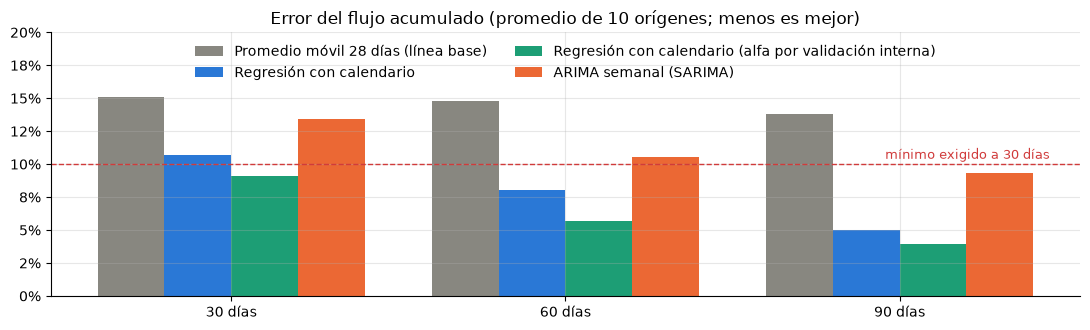

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ancho = 0.8 / len(resultados)
for i, r in enumerate(resultados):
    s = r.resumen()
    ax.bar(np.arange(3) + (i - (len(resultados) - 1) / 2) * ancho, [s[f"error_relativo_{h}"] for h in (30, 60, 90)], ancho,
           label=r.modelo, color=COLORES[r.modelo])
ax.axhline(UMBRAL_ERROR_30, color="#d03b3b", ls="--", lw=1)
ax.text(2.45, UMBRAL_ERROR_30 + 0.004, "mínimo exigido a 30 días", color="#d03b3b", ha="right", fontsize=9)
ax.set_xticks(range(3), ["30 días", "60 días", "90 días"])
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Error del flujo acumulado (promedio de 10 orígenes; menos es mejor)")
ax.set_ylim(0, 0.2)
ax.legend(frameon=False, ncol=2, loc="upper center")
plt.tight_layout()

### ¿Cuánto varía de un mes a otro?

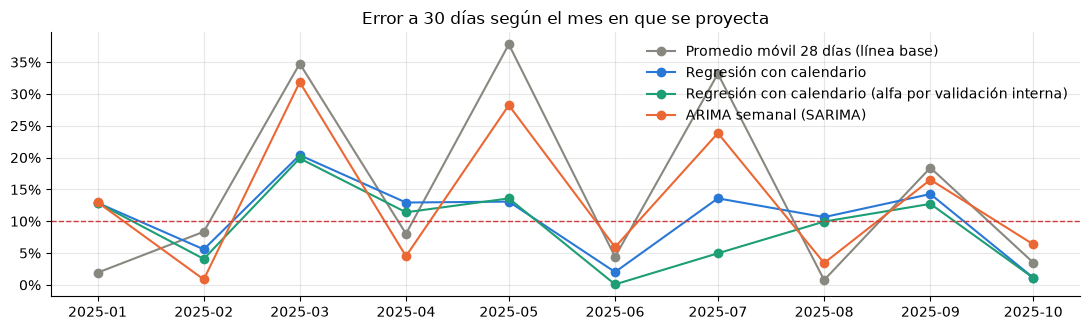

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.4))
for r in resultados:
    ax.plot(pd.to_datetime(r.por_origen["origen"]), r.por_origen["error_relativo_30"], marker="o",
            label=r.modelo, color=COLORES[r.modelo])
ax.axhline(UMBRAL_ERROR_30, color="#d03b3b", ls="--", lw=1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Error a 30 días según el mes en que se proyecta")
ax.legend(frameon=False)
plt.tight_layout()

### Proyección contra la realidad (último origen: octubre a diciembre de 2025)

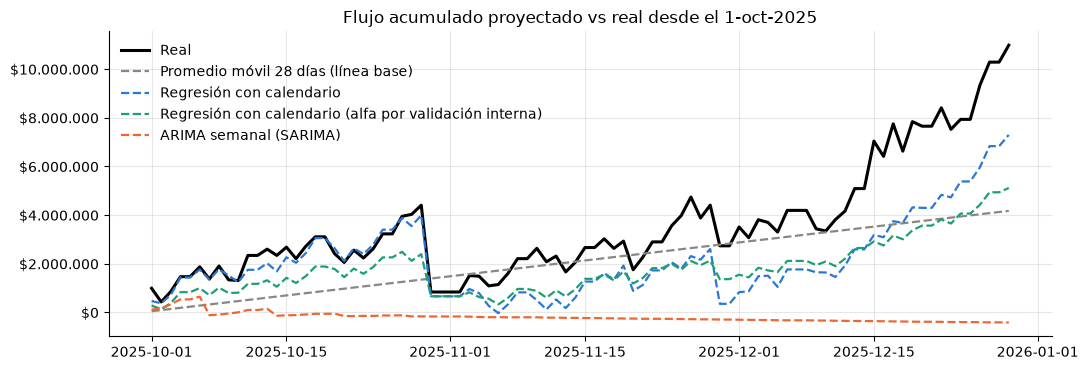

In [6]:
fig, ax = plt.subplots()
ultima = resultados[0].proyeccion_ultima
ax.plot(ultima.index, ultima["real_neto"].cumsum(), color="black", lw=2.2, label="Real")
for r in resultados:
    ax.plot(r.proyeccion_ultima.index, r.proyeccion_ultima["proyectado_neto"].cumsum(), color=COLORES[r.modelo],
            lw=1.6, ls="--", label=r.modelo)
ax.yaxis.set_major_formatter(pesos)
ax.set_title("Flujo acumulado proyectado vs real desde el 1-oct-2025")
ax.legend(frameon=False)
plt.tight_layout()

### Piso de ruido: ¿el mínimo era alcanzable?

Como el dataset es sintético, se puede simular la misma pyme con 200 semillas distintas. Lo que
cambia entre ellas es puro azar; un modelo perfecto, que conociera las reglas de la simulación,
tendría como error justamente esa variación.

In [7]:
piso = guardado["piso_de_ruido_30_dias"]
mejor = min(resultados[1:], key=lambda r: r.resumen()["error_relativo_30"])
print(f"Piso de ruido a 30 días (modelo perfecto): {piso['error_relativo_promedio']:.1%}")
print(f"Mejor candidato ({mejor.modelo}):           {mejor.resumen()['error_relativo_30']:.1%}")
print(f"Mínimo exigido:                             {UMBRAL_ERROR_30:.0%}")

Piso de ruido a 30 días (modelo perfecto): 5.1%
Mejor candidato (Regresión con calendario (alfa por validación interna)):           9.1%
Mínimo exigido:                             10%


El mínimo de 10 % está por encima del piso (5,1 %): es alcanzable y no hay que relajarlo. Con alfa fijo
en 1, la regresión se equivocaba el doble que un modelo perfecto: la diferencia era del modelo y no
del azar, y por eso valía la pena elegir mejor alfa.

### Exploración posterior (no se usa para decidir)

Después de ver los resultados de la primera comparación se probaron variantes de la regresión.
Se muestran porque explican de dónde salió el candidato con alfa interno, pero **no se usan para
decidir**: elegir un parámetro mirando los
mismos meses con que se evalúa infla el resultado.

In [8]:
filas = []
for alfa in (0.3, 1.0, 3.0, 10.0):
    r = evaluar(RegresionCalendario(alfa=alfa), serie, origenes).resumen()
    filas.append({"alfa (ridge)": alfa, "Error 30 d": r["error_relativo_30"], "Error 90 d": r["error_relativo_90"]})
pd.DataFrame(filas).style.format({"Error 30 d": "{:.1%}", "Error 90 d": "{:.1%}"}).hide(axis="index")

alfa (ridge),Error 30 d,Error 90 d
0.300000,11.0%,5.4%
1.000000,10.7%,5.0%
3.000000,9.6%,4.2%
10.000000,8.0%,3.6%


Una penalización mayor (alfa 3 o 10) baja el error a 30 días cerca o por debajo del 10 %. Para
usarla de verdad, alfa se tiene que elegir **dentro** de cada entrenamiento (validación con los
meses anteriores al origen) y confirmarse con datos que no se hayan mirado: eso hace el candidato
*con alfa por validación interna* y la confirmación de abajo. Modelar las ventas
en escala logarítmica también se probó y no mejoró a 30 días (11,4 %).

## Decisión en el dataset principal

In [9]:
eleccion = elegir(resultados)
for e in eleccion["candidatos"]:
    print(f"{e['modelo']}: error 30 d {e['error_relativo_30']:.1%} "
          f"(umbral {'OK' if e['cumple_umbral'] else 'NO'}), mejora sobre la base {e['mejora_sobre_base']:.0%} "
          f"({'OK' if e['cumple_mejora'] else 'NO'})")
print("\n" + eleccion["conclusion"])

Regresión con calendario: error 30 d 10.7% (umbral NO), mejora sobre la base 29% (OK)
Regresión con calendario (alfa por validación interna): error 30 d 9.1% (umbral OK), mejora sobre la base 40% (OK)
ARIMA semanal (SARIMA): error 30 d 13.5% (umbral NO), mejora sobre la base 11% (OK)

Se usa Regresión con calendario (alfa por validación interna).


## Confirmación con un dataset no mirado

Otra simulación de la misma pyme (semilla 2026), generada después de fijar el protocolo y no usada
para nada antes. Un candidato se aprueba solo si cumple las dos reglas **en ambos** datasets.

In [10]:
resultados_conf = [evaluar(m, serie_confirmacion, origenes) for m in candidatos()]
eleccion_conf = elegir(resultados_conf)
for e in eleccion_conf["candidatos"]:
    print(f"{e['modelo']}: error 30 d {e['error_relativo_30']:.1%} "
          f"(umbral {'OK' if e['cumple_umbral'] else 'NO'}), mejora sobre la base {e['mejora_sobre_base']:.0%} "
          f"({'OK' if e['cumple_mejora'] else 'NO'})")
final = confirmar(eleccion, eleccion_conf)
print("\n" + final["conclusion"])

Regresión con calendario: error 30 d 9.3% (umbral OK), mejora sobre la base 39% (OK)
Regresión con calendario (alfa por validación interna): error 30 d 7.7% (umbral OK), mejora sobre la base 50% (OK)
ARIMA semanal (SARIMA): error 30 d 14.4% (umbral NO), mejora sobre la base 6% (NO)

Se usa Regresión con calendario (alfa por validación interna): cumple el desempeño mínimo en ambos datasets.


## Decisión

**Se elige la regresión con calendario con alfa por validación interna.** Queda en 9,1 % a 30 días
en el dataset principal y en 7,7 % en el de confirmación (máximo 10 %), y mejora a la línea base
en 40 % y 50 %. Es la única que cumple en ambos: la regresión con alfa fijo en 1 cumple en la
confirmación (9,3 %) pero no en el principal (10,7 %).

Cumple **en promedio**: en 5 de los 10 meses del principal y en 3 de los 10 de la confirmación el
error a 30 días pasa del 10 % (hasta ~20 %). Por eso, al integrarla, la proyección estadística
acompaña a la de documentos y no la reemplaza. Detalle en `MODELO.md`.